<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/TugasPraktikum_JS6_Regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


import library

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

pemahaman dan deskripsi terhadap dataset

In [6]:
df = pd.read_csv("/content/drive/MyDrive/Data Saya/semester 5/pembelajaran mesin/insurance.csv")
print("Ukuran dataset (baris, kolom):", df.shape)
df.head()

Ukuran dataset (baris, kolom): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [8]:
df.describe()

,age,bmi,children,charges
count,"1,338.0000","1,338.0000","1,338.0000","1,338.0000"
mean,39.2070,30.6634,1.0949,"13,270.4223"
std,14.0500,6.0982,1.2055,"12,110.0112"
min,18.0000,15.9600,0.0000,"1,121.8739"
25%,27.0000,26.2963,0.0000,"4,740.2872"
50%,39.0000,30.4000,1.0000,"9,382.0330"
75%,51.0000,34.6938,2.0000,"16,639.9125"
max,64.0000,53.1300,5.0000,"63,770.4280"


In [9]:
print("Jumlah missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Jumlah missing value per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris duplikat: 1


tidak ada missing value. terhadap 1 baris duplikat, karena hanya 1 dari 1338 baris (kemungkinan dua orang berbeda dengan karakteristik identik) dan pengaruhnya dapat diabaikan, baris tersebut tetap dipertahankan.

visualisasi data

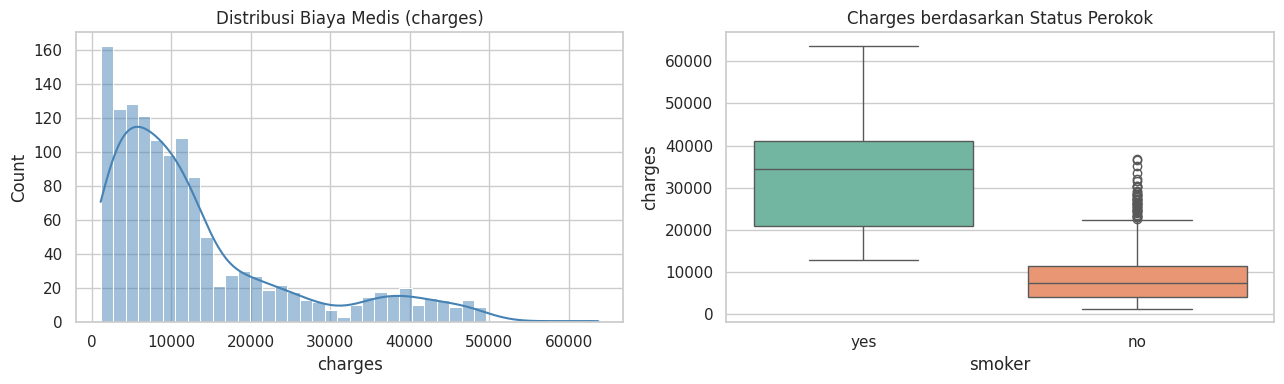

        count        mean      median
smoker                               
no       1064  8,434.2683  7,345.4053
yes       274 32,050.2318 34,456.3485


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["charges"], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribusi Biaya Medis (charges)")
sns.boxplot(data=df, x="smoker", y="charges", ax=ax[1], palette="Set2", hue="smoker", legend=False)
ax[1].set_title("Charges berdasarkan Status Perokok")
plt.tight_layout(); plt.show()

print(df.groupby("smoker")["charges"].agg(["count", "mean", "median"]))

temuan: distribusi charges  condong ke kanan dengan beberapa nilai ekstream tinggi. perokok memiliki biaya medis yang jauh lebih tinggi dibanding bukan perokok.

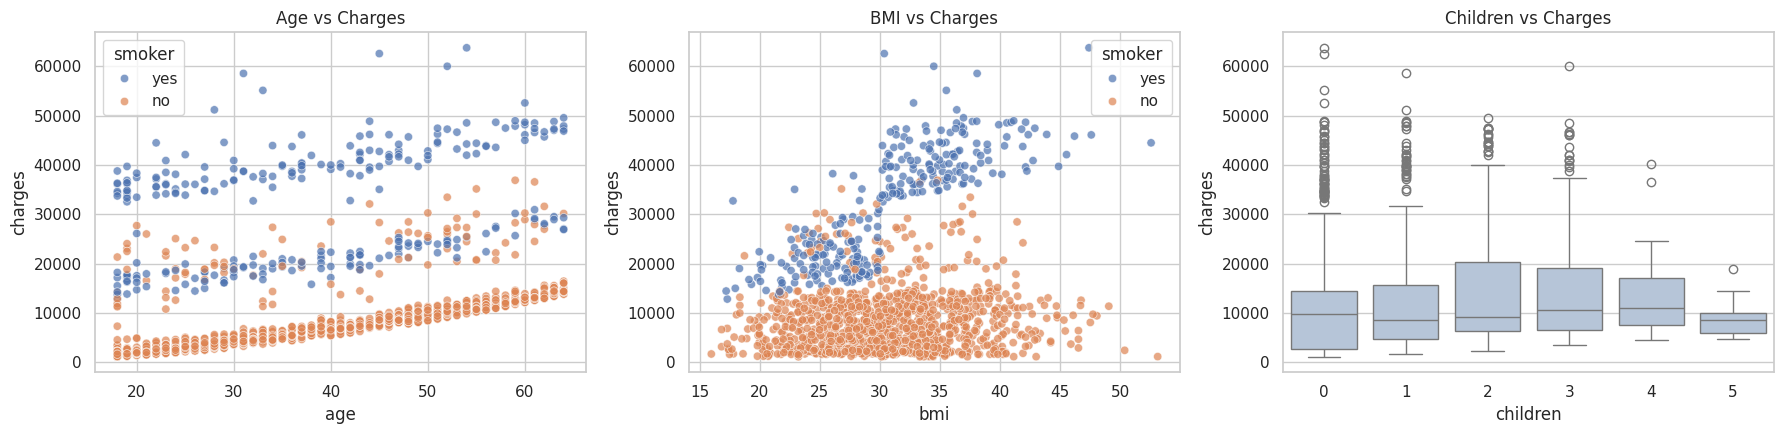

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=ax[0])
ax[0].set_title("Age vs Charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7, ax=ax[1])
ax[1].set_title("BMI vs Charges")
sns.boxplot(data=df, x="children", y="charges", ax=ax[2], color="lightsteelblue")
ax[2].set_title("Children vs Charges")
plt.tight_layout(); plt.show()

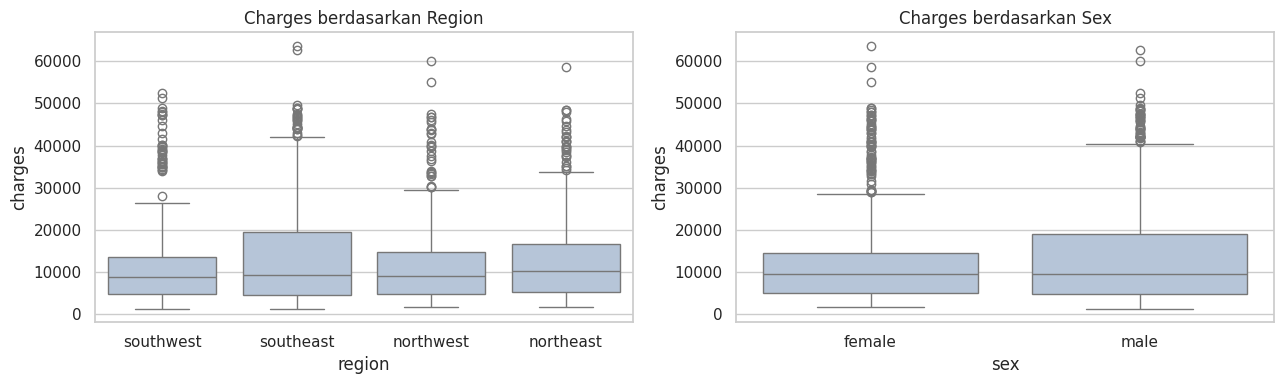

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="region", y="charges", ax=ax[0], color="lightsteelblue")
ax[0].set_title("Charges berdasarkan Region")
sns.boxplot(data=df, x="sex", y="charges", ax=ax[1], color="lightsteelblue")
ax[1].set_title("Charges berdasarkan Sex")
plt.tight_layout(); plt.show()

identifikasi variabel bebas (fitur) dan variabel target.

In [13]:
target = "charges"
features = ["age", "sex", "bmi", "children", "smoker", "region"]

X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df[target]

print("Fitur setelah encoding:", list(X.columns))
X.head()

Fitur setelah encoding: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.9000,0,0,1,0,0,1
1,18,33.7700,1,1,0,0,1,0
2,28,33.0000,3,1,0,0,1,0
3,33,22.7050,0,1,0,1,0,0
4,32,28.8800,0,1,0,1,0,0


korelasi antara variabel (setelah encoding) terhadap target

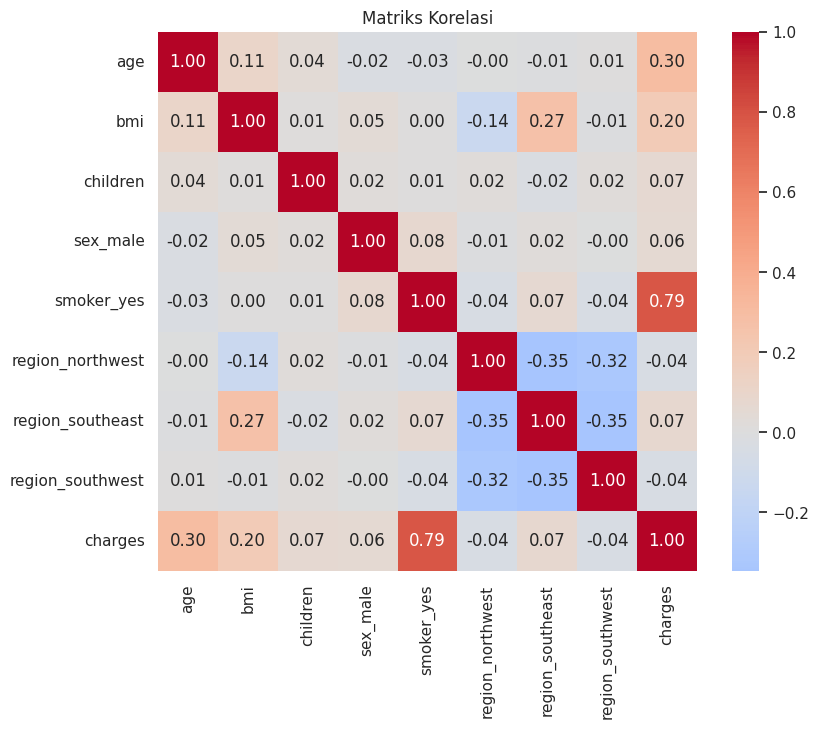

,charges
smoker_yes,0.7873
age,0.2990
bmi,0.1983
region_southeast,0.0740
children,0.0680
sex_male,0.0573
region_northwest,-0.0399
region_southwest,-0.0432


In [14]:
corr = pd.concat([X, y], axis=1).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriks Korelasi")
plt.show()

corr[target].drop(target).sort_values(ascending=False)

membagi data latih dan data uji

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data latih :", X_train.shape, y_train.shape)
print("Data uji   :", X_test.shape, y_test.shape)

Data latih : (1070, 8) (1070,)
Data uji   : (268, 8) (268,)


feature scaling

In [16]:
num_cols = ["age", "bmi", "children"]

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit hanya di data latih
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # data uji: transform saja

X_train_s[num_cols].describe().loc[["mean", "std"]]

,age,bmi,children
mean,-0.0000,-0.0000,-0.0000
std,1.0005,1.0005,1.0005


membuat model multiple linear regression

model: $\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$

In [17]:
model = LinearRegression()
model

LinearRegression()

melatih model dan memprediksi data uji

In [18]:
model.fit(X_train_s, y_train)

y_pred_train = model.predict(X_train_s)
y_pred_test = model.predict(X_test_s)

hasil = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred_test,
    "Selisih": y_test.values - y_pred_test,
}).head(10)
hasil

,Aktual,Prediksi,Selisih
0,"9,095.0683","8,969.5503",125.5180
1,"5,272.1758","7,068.7474","-1,796.5716"
2,"29,330.9832","36,858.4109","-7,527.4278"
3,"9,301.8936","9,454.6785",-152.7850
4,"33,750.2918","26,973.1735","6,777.1183"
5,"4,536.2590","10,864.1132","-6,327.8542"
6,"2,117.3389",170.2808,"1,947.0580"
7,"14,210.5359","16,903.4503","-2,692.9143"
8,"3,732.6251","1,092.4309","2,640.1942"
9,"10,264.4421","11,218.3432",-953.9011


koefisien model

In [19]:
koef = pd.DataFrame({
    "Fitur": X.columns,
    "Koefisien (scaled)": model.coef_,
}).sort_values("Koefisien (scaled)", key=abs, ascending=False)

print(f"Intercept (scaled): {model.intercept_:,.2f}")
koef

Intercept (scaled): 8,955.24


,Fitur,Koefisien (scaled)
4,smoker_yes,"23,651.1289"
0,age,"3,614.9754"
1,bmi,"2,036.2281"
7,region_southwest,-809.7994
6,region_southeast,-657.8643
2,children,516.8902
5,region_northwest,-370.6773
3,sex_male,-18.5917


koefisien model tanpa scaling

In [20]:
model_raw = LinearRegression().fit(X_train, y_train)

koef_raw = pd.DataFrame({"Fitur": X.columns, "Koefisien (USD)": model_raw.coef_})
print(f"Intercept: {model_raw.intercept_:,.2f}")
koef_raw.sort_values("Koefisien (USD)", key=abs, ascending=False)

Intercept: -11,931.22


,Fitur,Koefisien (USD)
4,smoker_yes,"23,651.1289"
7,region_southwest,-809.7994
6,region_southeast,-657.8643
2,children,425.2788
5,region_northwest,-370.6773
1,bmi,337.0926
0,age,256.9757
3,sex_male,-18.5917


evaluasi model

In [21]:
def evaluasi(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R²": r2_score(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

hasil_eval = pd.DataFrame({
    "Data Latih": evaluasi(y_train, y_pred_train),
    "Data Uji": evaluasi(y_test, y_pred_test),
})
hasil_eval

,Data Latih,Data Uji
R²,0.7417,0.7836
MSE,"37,277,681.7020","33,596,915.8514"
RMSE,"6,105.5452","5,796.2847"
MAE,"4,208.2346","4,181.1945"


In [22]:
r2 = r2_score(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)

print("=== Hasil Evaluasi pada Data Uji ===")
print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:,.2f}")
print(f"RMSE      : {np.sqrt(mse):,.2f}")
print(f"MAE       : {mae:,.2f}")

=== Hasil Evaluasi pada Data Uji ===
R-squared : 0.7836
MSE       : 33,596,915.85
RMSE      : 5,796.28
MAE       : 4,181.19


validasi tambahan: pengaruh scaling dan cross validation

In [23]:
# 1) Apakah scaling mengubah hasil prediksi?
r2_raw = r2_score(y_test, model_raw.predict(X_test))
print(f"R² data uji TANPA scaling : {r2_raw:.6f}")
print(f"R² data uji DENGAN scaling: {r2:.6f}")

# 2) 5-fold cross-validation pada seluruh data (agar hasil tidak bergantung pada satu split)
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("\nR² 5-fold CV:", np.round(cv_r2, 4))
print(f"Rata-rata    : {cv_r2.mean():.4f}  (± {cv_r2.std():.4f})")

R² data uji TANPA scaling : 0.783593
R² data uji DENGAN scaling: 0.783593

R² 5-fold CV: [0.7615 0.7065 0.7781 0.7327 0.7556]
Rata-rata    : 0.7469  (± 0.0249)


visualisasi hasil prediksi

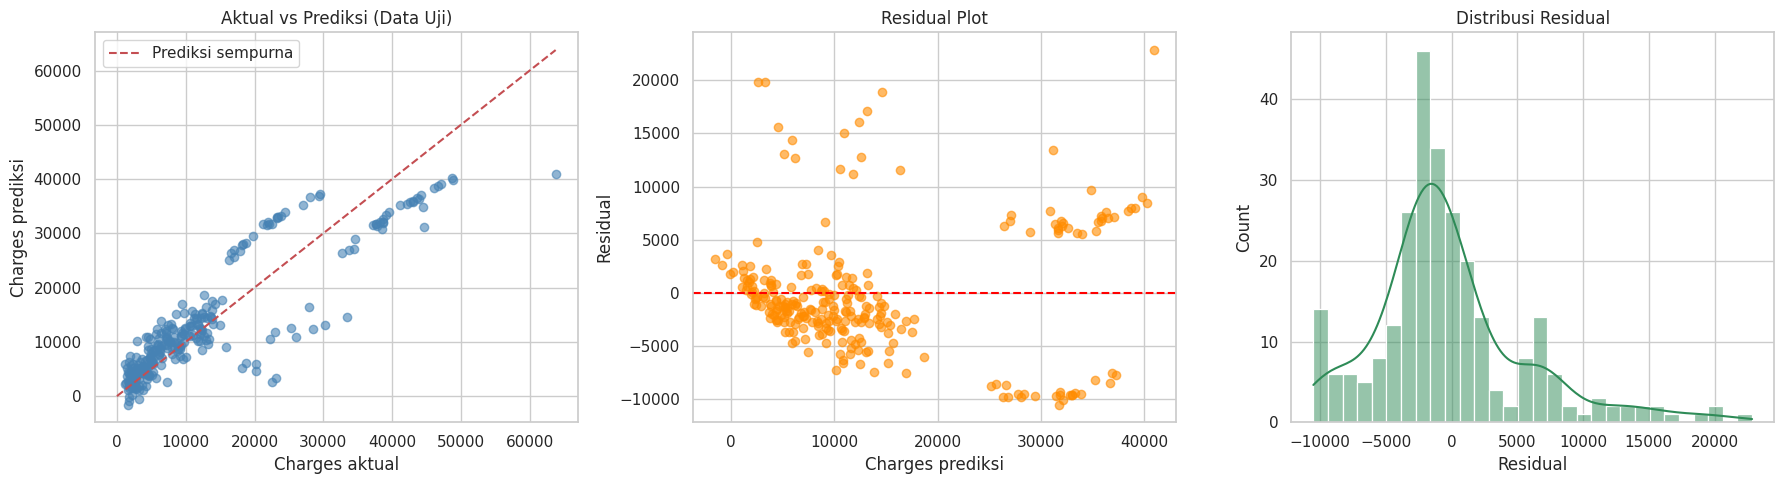

In [24]:
residual = y_test - y_pred_test

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Aktual vs Prediksi
ax[0].scatter(y_test, y_pred_test, alpha=0.6, color="steelblue")
lim = [0, max(y_test.max(), y_pred_test.max())]
ax[0].plot(lim, lim, "r--", label="Prediksi sempurna")
ax[0].set_xlabel("Charges aktual"); ax[0].set_ylabel("Charges prediksi")
ax[0].set_title("Aktual vs Prediksi (Data Uji)"); ax[0].legend()

# Residual plot
ax[1].scatter(y_pred_test, residual, alpha=0.6, color="darkorange")
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Charges prediksi"); ax[1].set_ylabel("Residual")
ax[1].set_title("Residual Plot")

# Distribusi residual
sns.histplot(residual, bins=30, kde=True, ax=ax[2], color="seagreen")
ax[2].set_xlabel("Residual"); ax[2].set_title("Distribusi Residual")

plt.tight_layout(); plt.show()

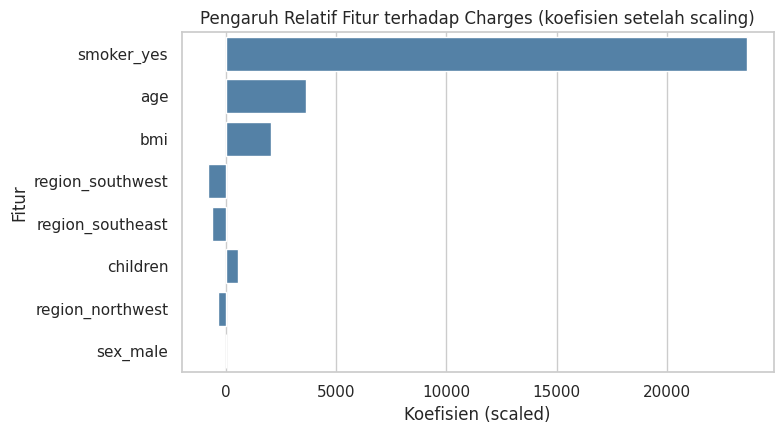

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=koef, y="Fitur", x="Koefisien (scaled)", color="steelblue", ax=ax)
ax.set_title("Pengaruh Relatif Fitur terhadap Charges (koefisien setelah scaling)")
plt.tight_layout(); plt.show()

In [26]:
# Kinerja per kelompok perokok (data uji)
cek = pd.DataFrame({"smoker": X_test["smoker_yes"], "aktual": y_test, "prediksi": y_pred_test})
for s, g in cek.groupby("smoker"):
    print(f"{'Perokok' if s else 'Bukan perokok':14s} | n={len(g):3d} | R²={r2_score(g.aktual, g.prediksi):.3f} | MAE={mean_absolute_error(g.aktual, g.prediksi):,.0f}")

Bukan perokok  | n=214 | R²=0.330 | MAE=3,130
Perokok        | n= 54 | R²=0.378 | MAE=8,348


analisis hasil

**Kinerja model.** Pada data uji, model memperoleh **R² ≈ 0,784**, **MSE ≈ 33,6 juta** (RMSE ≈ 5.796 USD), dan **MAE ≈ 4.181 USD**. Artinya model menjelaskan sekitar 78% variasi biaya medis, dan rata-rata prediksi meleset ±4.181 USD (rata-rata `charges` sekitar 13.270 USD). R² data latih (≈0,742) tidak lebih tinggi dari data uji, jadi **tidak ada tanda overfitting**; selisihnya hanya karena variasi pembagian data. Hasil 5-fold cross-validation (R² rata-rata ≈ 0,75 ± 0,02) menunjukkan performa yang konsisten.

**Pengaruh scaling.** R² dengan dan tanpa scaling identik, sesuai teori bahwa OLS tidak sensitif terhadap skala fitur. Manfaat scaling di sini terletak pada perbandingan koefisien antar fitur.

**Interpretasi koefisien (satuan USD, model tanpa scaling), dengan variabel lain tetap:**
- `smoker_yes` ≈ **+23.651**: faktor paling dominan; perokok rata-rata menanggung biaya ≈ 23,6 ribu USD lebih tinggi.
- `age` ≈ +257 per tahun, `bmi` ≈ +337 per satu poin BMI, `children` ≈ +425 per anak: semuanya menaikkan biaya. Setelah scaling, di antara fitur numerik urutan pengaruhnya adalah age > bmi > children; `smoker_yes` tetap yang terbesar.
- `sex` (≈ −19) dan `region` (selisih ratusan USD terhadap *northeast*) pengaruhnya kecil dan tidak menonjol.

**Keterbatasan (dari plot residual).**
1. Pada plot aktual vs prediksi, titik tidak mengikuti garis diagonal dengan rapat dan membentuk kelompok (cluster). Pada data uji, model rata-rata **meremehkan biaya perokok dengan BMI ≥ 30 sekitar 7.100 USD**, sebaliknya **melebihkan biaya perokok ber-BMI < 30 sekitar 7.900 USD**. Model juga menghasilkan 4 prediksi negatif (biaya tidak mungkin negatif). MAE pada perokok (≈8.300 USD) jauh lebih besar daripada bukan perokok (≈3.100 USD).
2. Residual **tidak berpola acak dan tidak homoskedastis**: besar galat berkorelasi positif (≈0,54) dengan nilai prediksi, dan distribusinya condong ke kanan. Ini melanggar asumsi regresi linear klasik.
3. Penyebab utamanya: hubungan sebenarnya **tidak sepenuhnya linear/aditif**. Efek BMI hanya besar pada perokok (interaksi `smoker × obesitas`), dan efek usia sedikit melengkung. Model linear biasa memaksakan efek yang sama untuk semua kelompok.

Bagian berikut mencoba membuktikan dugaan ini.

Menangkap non linearitas dan interaksi

In [27]:
# Fitur tambahan: interaksi perokok x obesitas (BMI >= 30) dan usia kuadrat
X2 = X.copy()
X2["smoker_obese"] = X["smoker_yes"] * (df["bmi"] >= 30).astype(int)
X2["age_sq"] = df["age"] ** 2

X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.2, random_state=42)  # split sama
m2 = LinearRegression().fit(X2_tr, y2_tr)
p2 = m2.predict(X2_te)

perbandingan = pd.DataFrame({
    "Model dasar": evaluasi(y_test, y_pred_test),
    "Model + interaksi & age²": evaluasi(y2_te, p2),
})
perbandingan

,Model dasar,Model + interaksi & age²
R²,0.7836,0.8760
MSE,"33,596,915.8514","19,252,350.1563"
RMSE,"5,796.2847","4,387.7500"
MAE,"4,181.1945","2,420.4672"


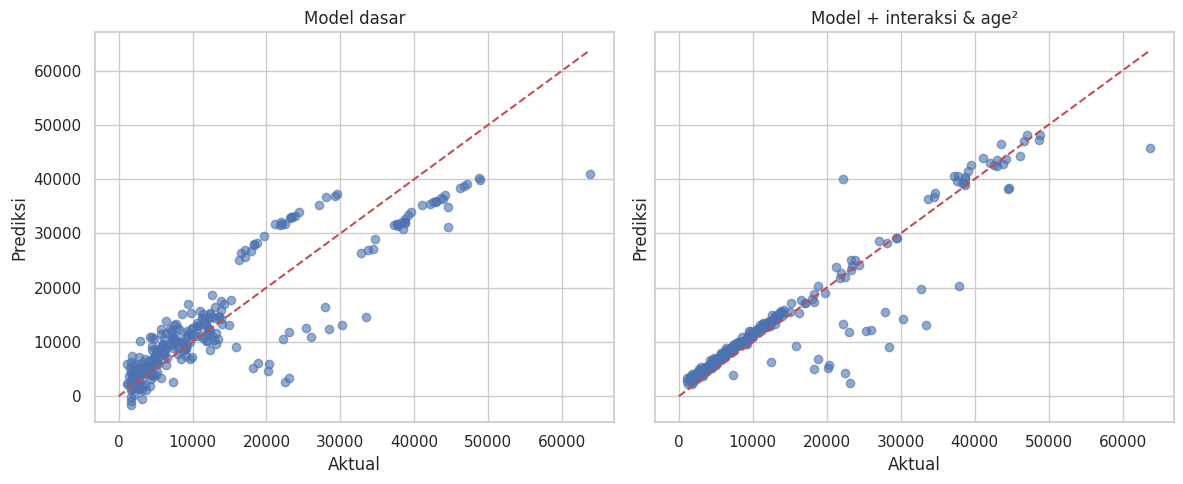

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, pred, judul in zip(ax, [y_pred_test, p2], ["Model dasar", "Model + interaksi & age²"]):
    a.scatter(y_test, pred, alpha=0.6)
    a.plot(lim, lim, "r--")
    a.set_title(judul); a.set_xlabel("Aktual"); a.set_ylabel("Prediksi")
plt.tight_layout(); plt.show()